In [20]:
import scanpy as sc
import anndata as ad
ad.settings.allow_write_nullable_strings = True

In [2]:
adata = sc.read_h5ad('/Users/G20748795/Desktop/lab/Tumor/integrated.h5ad')

In [3]:
sc.pp.neighbors(adata, use_rep='X_scVI_20', n_neighbors=30)
sc.tl.umap(adata)

C:\Users\G20748795\AppData\Local\Temp\2\ipykernel_11664\3645299135.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=0.3)


22 clusters


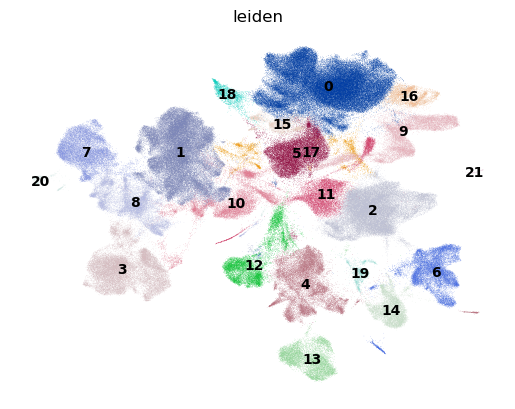

In [11]:
sc.tl.leiden(adata, resolution=0.3)

print(f"{adata.obs['leiden'].nunique()} clusters")
sc.pl.umap(adata, color='leiden', legend_loc='on data', frameon=False)

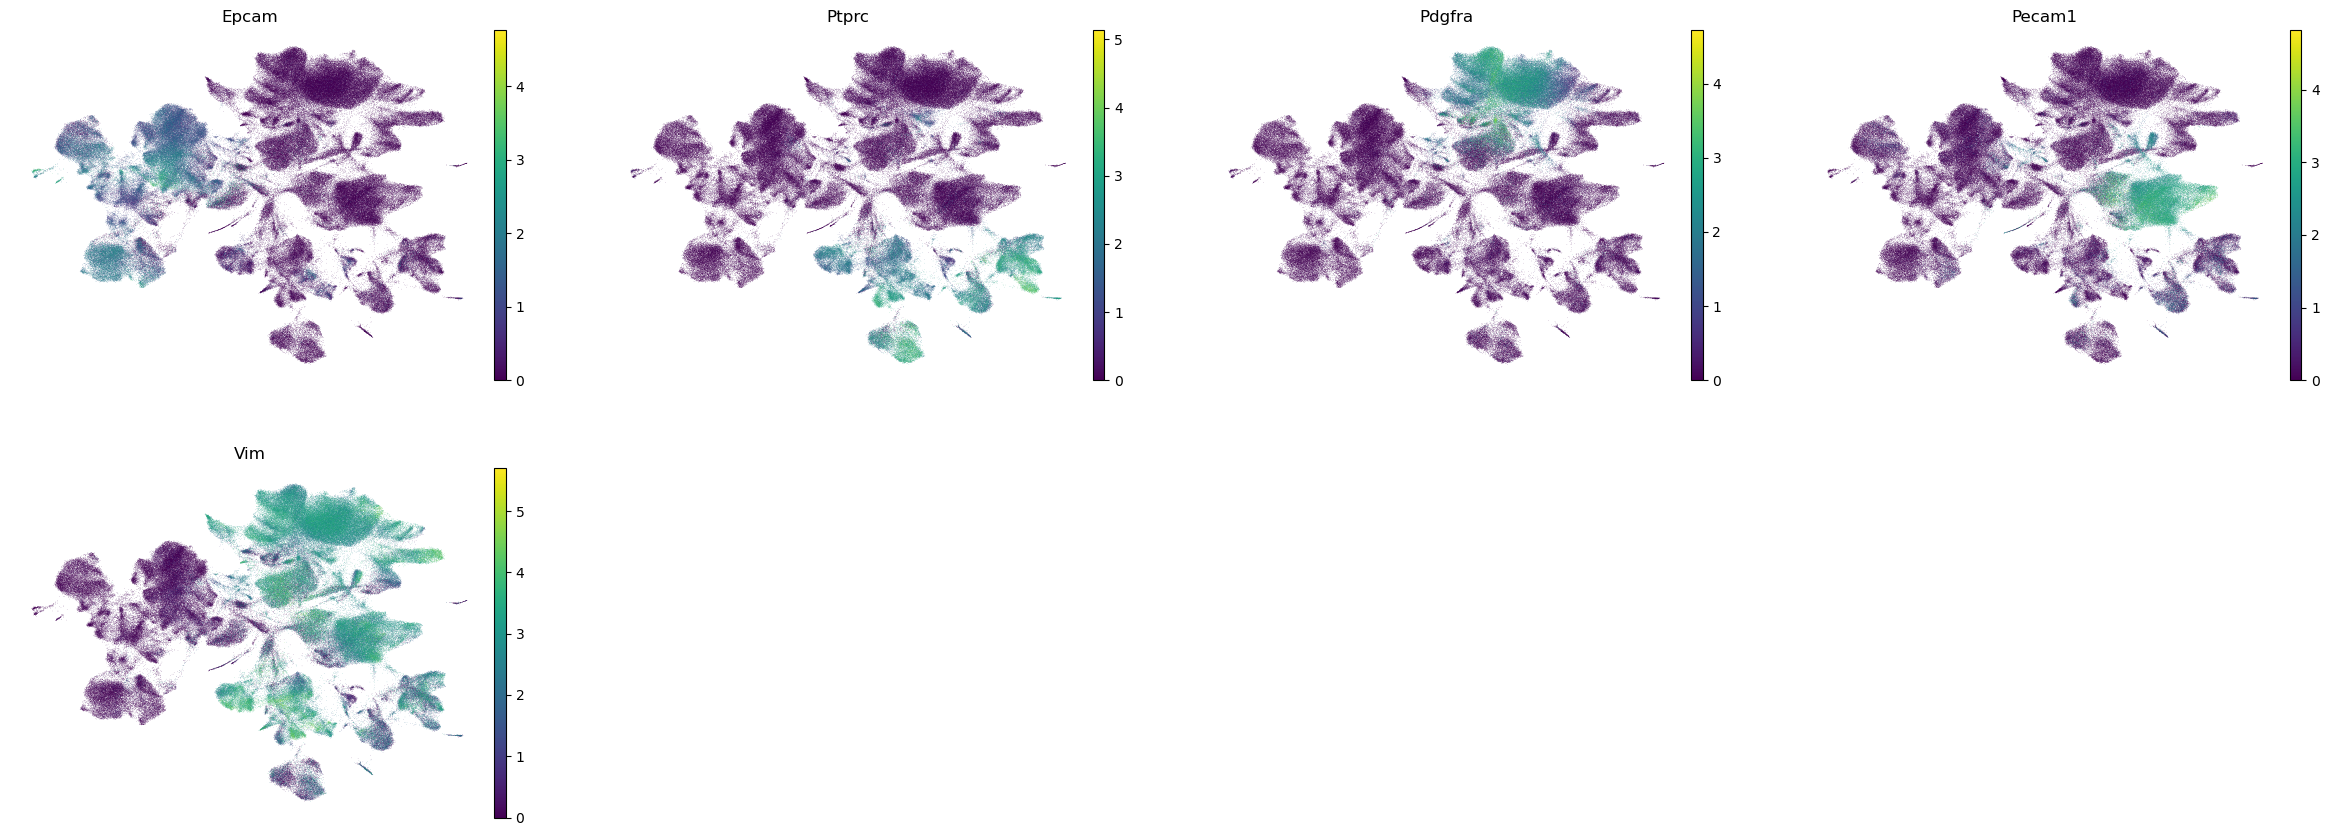

In [5]:
sc.pl.umap(adata, color=['Epcam', 'Ptprc', 'Pdgfra', 'Pecam1','Vim'], frameon=False)

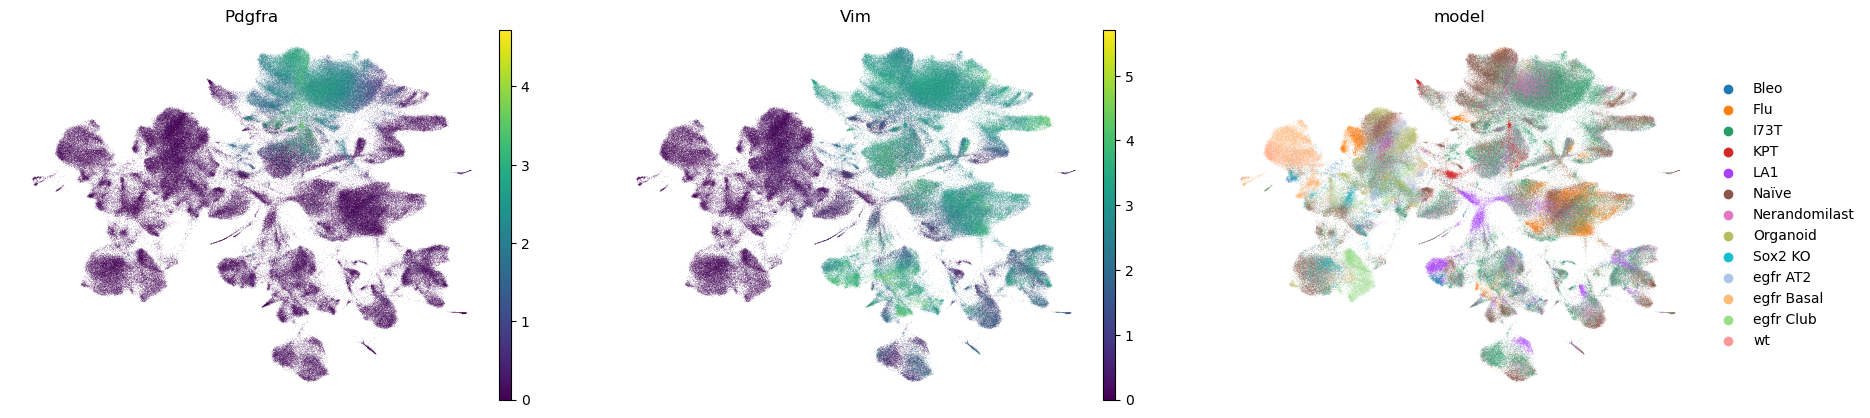

In [10]:
sc.pl.umap(adata, color=['Pdgfra', 'Vim','model'], frameon=False)

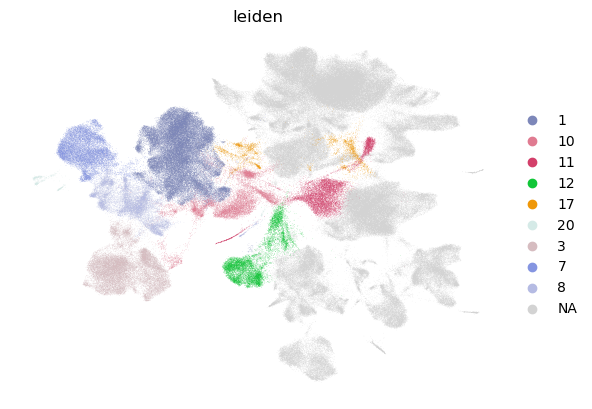

In [22]:
sc.pl.umap(adata, color='leiden', groups=['1','3','7','8','10','11','12','17','20'], frameon=False)

In [24]:
epithelial = adata[adata.obs['leiden'].isin(['1','3','7','8','10','11','12','17','20'])]
epithelial

View of AnnData object with n_obs × n_vars = 141322 × 40194
    obs: 'bead', 'sample', 'type', 'model', 'age', 'original_file', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'mt_cut', 'ribo_cut', 'batch', 'nCount_RNA', 'nFeature_RNA', 'nCount_SCT', 'nFeature_SCT', 'experiment', 'condition', 'treatment', 'mutation', 'timepoint', 'lineage', 'celltype_1_label', 'KAC_Han_score', 'sig14_score', '_scvi_batch', '_scvi_labels', 'leiden'
    var: 'n_cells'
    uns: '_scvi_manager_uuid', '_scvi_uuid', 'log1p', 'model_colors', 'neighbors', 'sample_colors', 'umap', 'leiden', 'leiden_colors'
    obsm: 'X_scVI_10', 'X_scVI_20', 'X_scVI_30', 'X_umap'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [25]:
epithelial.write_h5ad('epithelial.h5ad')